In [11]:
import numpy as np 
import seaborn as sns


def mean(x):
    return np.sum(x) / len(x)

def bootci(est, x, q):
    estimates = [est(np.random.choice(x, len(x), replace=True)) for _ in range(1000)]
    low, high = (1-q) / 2, (1+q) / 2
    return estimates, np.quantile(estimates, [low, high])

In [12]:
x = np.random.normal(size=100000)
q = 0.99
estimates, ci = bootci(mean, x, q)

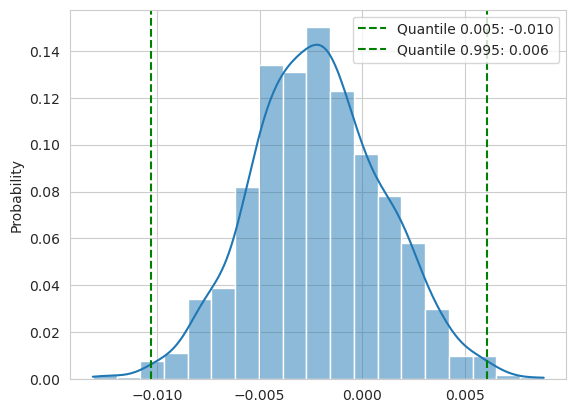

In [13]:
sns.set_style("whitegrid")
ax = sns.histplot(estimates, bins=int(1 + 1.59 * np.log(len(x))), kde=True, stat='probability')
ax.axvline(ci[0], color='green', linestyle='--', label=f'Quantile {(1-q) / 2:.3f}: {ci[0]:.3f}')
ax.axvline(ci[1], color='green', linestyle='--', label=f'Quantile {(1+q) / 2:.3f}: {ci[1]:.3f}')
ax.legend()